# Criminalidad en regiones con mayor canon minero
#### Grupo 3
**Integrantes:** 
- Joe Anderson Chuque Vergara
- Roberto Alonso Briceño Alva
- Luis Alejandro Zegarra Misajel


## 1. Introducción

El canon minero es la parte de los ingresos generados por la explotación de recursos mineros que reciben los gobiernos regionales y locales. En el Perú, estos ingresos pueden representar un monto importante del presupuesto de las regiones donde se concentra la actividad minera.

Una mayor disponibilidad de recursos puede mejorar la provisión de servicios y la seguridad. Sin embargo, la actividad minera también puede traer migración, desigualdad, conflictos por recursos y economías ilegales. Una hipótesis frecuente es que las zonas con mucha riqueza minera atraen también a organizaciones criminales, precisamente por la cantidad de recursos que se mueven en ellas.

En este trabajo, la tasa de victimización por 100 mil habitantes se utiliza como **proxy de la inseguridad y la criminalidad** en cada región, y el canon minero per cápita como **aproximación de la presencia o influencia de la minería formal**. No se cuenta con datos directos de minería ilegal, por lo que esta no se mide en el análisis (variable inobservable) y se discute como limitación. Dado que la relación entre ambas variables no es evidente, se justifica un diagnóstico con datos regionales.

Este trabajo analiza un panel de 24 departamentos y el Callao entre 2018 y 2025, con el objetivo de describir los patrones territoriales y estimar la asociación entre el canon minero per cápita y la tasa de victimización por 100 mil habitantes. Se utiliza todo el periodo disponible desde 2018 para contar con más observaciones por región.

Los resultados se interpretan como asociaciones condicionales y no como efectos causales, ya que se trabaja con datos observacionales a nivel regional.

# 2. Pregunta de investigación e hipótesis

**Pregunta de investigación:** ¿Cuál es la asociación entre un mayor canon minero per cápita, rezagado un año, y la tasa de victimización por 100 mil habitantes en las regiones del Perú?

**Hipótesis:**
- **H0:** el canon minero per cápita no se asocia con la victimización (β1 = 0).
- **H1a:** un mayor canon se asocia con menor victimización (β1 < 0), por mayor gasto público, empleo y provisión de servicios.
- **H1b:** un mayor canon se asocia con mayor victimización (β1 > 0), por migración, desigualdad, conflictos por recursos y mayor atracción de economías ilegales y organizaciones criminales hacia zonas con más recursos.

# 3. Construccion de Variables

In [3]:
import os
import numpy as np
import pandas as pd
import pyreadstat

"""
Esribir la direccion en donde se descargo la carpeta "Parcial\BASE_DE_DATOS_PHYTON"
Ejemplo: 
"""
# C:\Users\usuario\OneDrive\Desktop\PUCP\PYTHON\Parcial\BASE_DE_DATOS_PHYTON

RUTA = input("Pega la direccion de la carpeta BASE DE DATOS: ")
RUTA = RUTA.strip()        
RUTA = RUTA.replace('"', '')
if not os.path.exists(RUTA):
    print("OJO: esa carpeta no existe, revisa la direccion")
ANIOS = [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

<>:7: SyntaxWarning: invalid escape sequence '\B'
<>:7: SyntaxWarning: invalid escape sequence '\B'
C:\Users\usuario\AppData\Local\Temp\ipykernel_14636\3861030680.py:7: SyntaxWarning: invalid escape sequence '\B'
  Esribir la direccion en donde se descargo la carpeta "Parcial\BASE_DE_DATOS_PHYTON"


In [2]:
CARPETAS = {
    "enapres":   "Victimizacion",
    "pobreza":   "Pobreza",
    "migracion": "Migracion",
    "desempleo": "Desempleo",
    "gasto":     "Gasto en seguridad",
    "canon_loc": "Canon minero/Canon local",
    "canon_gr":  "Canon minero/Canon regional",
    "vab":       "Valor Agregado Bruto",
    "ipc":       "IPC",
    "poblacion": "Poblacion",
}

In [3]:
ARCH_IPC = "n02_indice-precios_al_consumidor-nivel_nacional_set26.xlsx"
ARCH_POBLACION = "6894980-peru-poblacion-total-proyectada-al-30-de-junio-de-cada-ano-segun-departamento-provincia-y-distrito-2018-2026.xlsx"

COD_DEP = {1: 'AMAZONAS', 2: 'ANCASH', 3: 'APURIMAC', 4: 'AREQUIPA', 5: 'AYACUCHO',
           6: 'CAJAMARCA', 7: 'CALLAO', 8: 'CUSCO', 9: 'HUANCAVELICA', 10: 'HUANUCO',
           11: 'ICA', 12: 'JUNIN', 13: 'LA LIBERTAD', 14: 'LAMBAYEQUE', 15: 'LIMA',
           16: 'LORETO', 17: 'MADRE DE DIOS', 18: 'MOQUEGUA', 19: 'PASCO', 20: 'PIURA',
           21: 'PUNO', 22: 'SAN MARTIN', 23: 'TACNA', 24: 'TUMBES', 25: 'UCAYALI'}

DEPTOS = list(COD_DEP.values())

REGION_NATURAL = {
    "TUMBES": "Costa", "PIURA": "Costa", "LAMBAYEQUE": "Costa", "LA LIBERTAD": "Costa",
    "ANCASH": "Costa", "LIMA": "Costa", "CALLAO": "Costa", "ICA": "Costa",
    "AREQUIPA": "Costa", "MOQUEGUA": "Costa", "TACNA": "Costa",
    "CAJAMARCA": "Sierra", "HUANUCO": "Sierra", "PASCO": "Sierra", "JUNIN": "Sierra",
    "HUANCAVELICA": "Sierra", "AYACUCHO": "Sierra", "APURIMAC": "Sierra",
    "CUSCO": "Sierra", "PUNO": "Sierra",
    "LORETO": "Selva", "UCAYALI": "Selva", "MADRE DE DIOS": "Selva",
    "SAN MARTIN": "Selva", "AMAZONAS": "Selva"}

# Victimizacion (factor de expansion)
CONFIG_VICTIM = {
    2018: ("P601", "FACTOR"),
    2019: ("P601", "FACTOR"),
    2020: ("P601", "FACTOR_CALIBRADO"),
    2021: ("P601", "FACTOR_CALIBRADO"),
    2022: ("P601", "FACTOR"),
    2023: ("P601", "FACTOR"),
    2024: ("P615", "FACTOR_CAP600B"),  
    2025: ("P424", "FACTOR_CAP400"),
}

# Orden final de las columnas
COLUMNAS_FINALES = [
    "depto", "victim_100k", "n_victim", "anio", "pobreza", "pobreza_extrema", "n_hogares",
    "migracion", "n_personas", "desempleo", "n_pea", "poblacion", "crec_pob", "gasto_seg",
    "canon_gr", "canon_loc", "vab_total", "vab_min", "vab_sin_min", "deflactor",
    "canon_total", "canon_pc_real", "canon_pc_real_l1", "ln_canon_l1",
    "gasto_seg_pc_real", "pbi_sinmin_pc", "ln_pbi_sinmin_pc", "prod_min_pc",
    "region_natural"]

In [4]:
# ============================================================
# 1. FUNCIONES PARA LEER ARCHIVOS Y LIMPIAR NOMBRES
# ============================================================
def armar_ruta(clave, nombre_archivo):
    carpeta = CARPETAS[clave]
    if carpeta == "":
        ruta = RUTA + "/" + nombre_archivo
    else:
        ruta = RUTA + "/" + carpeta + "/" + nombre_archivo
    return ruta


def leer_base(ruta, columnas=None, hoja=0, cabecera=0, tipos=None, html=False):
    # Separo el nombre del archivo por los puntos y nos quedamos con lo ultimo
    partes = ruta.split(".")
    extension = partes[-1].lower()

    if extension == "csv":
        df = pd.read_csv(ruta, encoding="latin1", sep=None, engine="python")
    elif extension == "dta":
        if columnas is None:
            df = pd.read_stata(ruta, convert_categoricals=False)
        else:
            df = pd.read_stata(ruta, convert_categoricals=False, columns=columnas)
    elif extension == "sav":
        df, meta = pyreadstat.read_sav(ruta)
    elif extension == "xls" or extension == "xlsx":
        if html == True:
            df = pd.read_html(ruta, encoding="latin1", decimal=".", thousands=",")
        else:
            df = pd.read_excel(ruta, sheet_name=hoja, header=cabecera, dtype=tipos)
    else:
        print("Extension no reconocida:", extension)
        df = None

    return df

In [5]:
def limpiar_texto(serie):
    serie = serie.astype(str).str.upper().str.strip()
    cambios = [("Á", "A"), ("É", "E"), ("Í", "I"), ("Ó", "O"), ("Ú", "U"), ("Ü", "U"), ("Ñ", "N")]
    for con_tilde, sin_tilde in cambios:
        serie = serie.str.replace(con_tilde, sin_tilde, regex=False)
    return serie


def limpiar_depto(serie):
    serie = limpiar_texto(serie)
    serie = serie.replace({"PROV. CONST. DEL CALLAO": "CALLAO",
                           "PROVINCIA CONSTITUCIONAL DEL CALLAO": "CALLAO",
                           "REGION LIMA": "LIMA",
                           "PROVINCIA DE LIMA": "LIMA",
                           "LIMA PROVINCIAS": "LIMA",
                           "LIMA METROPOLITANA": "LIMA"})
    return serie

In [6]:
# ============================================================
# 2. UNA FUNCION PARA CADA VARIABLE
# ============================================================

In [7]:
# ------------------------------------------------------------
# 2.1 VICTIMIZACION 
# ------------------------------------------------------------
def tasa_victim(df, anio, prefijo, factor):
    df.columns = df.columns.str.upper()

    items = []
    for c in df.columns:
        if c.startswith(prefijo + "_"):
            items.append(c)

    for c in items:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df[factor] = df[factor].astype(str).str.replace(",", ".")
    df[factor] = pd.to_numeric(df[factor], errors="coerce")
    df = df.copy()
    df["depto"] = limpiar_depto(df["NOMBREDD"])

    df["victima"] = (df[items] == 1).any(axis=1)
    df["respondio"] = df[items].isin([1, 2, 3]).any(axis=1)
    df["peso_victima"] = df["victima"] * df[factor]

    df = df[df["respondio"] & df[factor].notna()]

    g = df.groupby("depto")[["peso_victima", factor]].sum()
    tasa = g["peso_victima"] / g[factor] * 100000
    n = df.groupby("depto").size()

    salida = pd.DataFrame({"victim_100k": tasa, "n_victim": n}).reset_index()
    salida["anio"] = anio
    return salida


def calc_victimizacion():
    resultados = []
    for anio in ANIOS:
        # 2018 y 2019 son .sav, los demas son .csv
        if anio == 2018 or anio == 2019:
            archivo = "ENAPRES_" + str(anio) + ".sav"
        else:
            archivo = "ENAPRES_" + str(anio) + ".csv"

        df = leer_base(armar_ruta("enapres", archivo))
        prefijo = CONFIG_VICTIM[anio][0]
        factor = CONFIG_VICTIM[anio][1]
        resultados.append(tasa_victim(df, anio, prefijo, factor))

    panel = pd.concat(resultados, ignore_index=True)
    return panel[["depto", "victim_100k", "n_victim", "anio"]]

In [8]:
# ------------------------------------------------------------
# 2.2 POBREZA 
# ------------------------------------------------------------
def pobreza_un_anio(anio):
    df = leer_base(armar_ruta("pobreza", "pob_" + str(anio) + ".dta"))
    df.columns = df.columns.str.lower()

    df["pobreza"] = pd.to_numeric(df["pobreza"], errors="coerce")
    df["mieperho"] = pd.to_numeric(df["mieperho"], errors="coerce")
    df["factor07"] = pd.to_numeric(df["factor07"], errors="coerce")

    df["ubigeo"] = df["ubigeo"].astype(str).str.zfill(6)
    df["depto"] = df["ubigeo"].str[:2].astype(int).map(COD_DEP)

    df["facpob"] = df["factor07"] * df["mieperho"]
    df = df.dropna(subset=["pobreza", "facpob", "depto"]).copy()

    df["pobre"] = df["pobreza"].isin([1, 2]).astype(int)    
    df["extremo"] = (df["pobreza"] == 1).astype(int)        
    df["w_pobre"] = df["pobre"] * df["facpob"]
    df["w_extremo"] = df["extremo"] * df["facpob"]

    g = df.groupby("depto").agg(w_pobre=("w_pobre", "sum"),
                                w_extremo=("w_extremo", "sum"),
                                pob=("facpob", "sum"),
                                n_hogares=("pobre", "size")).reset_index()

    g["pobreza"] = g["w_pobre"] / g["pob"] * 100
    g["pobreza_extrema"] = g["w_extremo"] / g["pob"] * 100
    g["anio"] = anio
    return g[["depto", "anio", "pobreza", "pobreza_extrema", "n_hogares"]]


def calc_pobreza():
    resultados = []
    for anio in ANIOS:
        resultados.append(pobreza_un_anio(anio))
    return pd.concat(resultados, ignore_index=True)

In [9]:
# ------------------------------------------------------------
# 2.3 MIGRACION 
# ------------------------------------------------------------
def migracion_un_anio(anio):
    df = leer_base(armar_ruta("migracion", "migra_" + str(anio) + ".dta"),
                   columnas=["ubigeo", "p401f", "p401g", "factor07"])
    df.columns = df.columns.str.lower()

    df["ubigeo"] = df["ubigeo"].astype(str).str.replace(r"\.0$", "", regex=True).str.zfill(6)
    df["depto"] = df["ubigeo"].str[:2].astype(int).map(COD_DEP)

    df["p401f"] = pd.to_numeric(df["p401f"], errors="coerce")
    df["p401g"] = pd.to_numeric(df["p401g"], errors="coerce")
    df["factor07"] = pd.to_numeric(df["factor07"], errors="coerce")

    # Departamento donde vivia hace 5 años
    df["depto_prev"] = df["p401g"]
    filtro = df["p401g"] > 100
    df.loc[filtro, "depto_prev"] = df.loc[filtro, "p401g"] // 10000
    df["depto_prev"] = df["depto_prev"].map(COD_DEP)

    df = df[df["p401f"].isin([1, 2]) & df["depto"].notna() & df["factor07"].notna()].copy()

    df["migrante"] = ((df["p401f"] == 2)
                      & df["depto_prev"].notna()
                      & (df["depto_prev"] != df["depto"])).astype(int)

    df["w_mig"] = df["migrante"] * df["factor07"]

    g = df.groupby("depto").agg(w_mig=("w_mig", "sum"),
                                pob=("factor07", "sum"),
                                n_personas=("migrante", "size")).reset_index()
    g["migracion"] = g["w_mig"] / g["pob"] * 100
    g["anio"] = anio

    return g[["depto", "anio", "migracion", "n_personas"]]


def calc_migracion():
    resultados = []
    for anio in ANIOS:
        resultados.append(migracion_un_anio(anio))
    return pd.concat(resultados, ignore_index=True)

In [10]:
# ------------------------------------------------------------
# 2.4 DESEMPLEO 
# ------------------------------------------------------------
def desempleo_un_anio(anio):
    df = leer_base(armar_ruta("desempleo", "desempleo_" + str(anio) + ".dta"))
    df.columns = df.columns.str.upper()

    if "FAC500A" in df.columns:
        factor = "FAC500A"
    elif "FAC500" in df.columns:
        factor = "FAC500"
    else:
        raise KeyError(str(anio) + ": no encontre el factor de expansion")

    df = df[["UBIGEO", "OCU500", factor]].copy()
    df["OCU500"] = pd.to_numeric(df["OCU500"], errors="coerce")
    df[factor] = pd.to_numeric(df[factor], errors="coerce")
    df["UBIGEO"] = df["UBIGEO"].astype(str).str.replace(r"\.0$", "", regex=True).str.zfill(6)
    df["cod_dpto"] = df["UBIGEO"].str[:2].astype(int)

    # PEA = ocupados (1) + desocupados abiertos (2) + desocupados ocultos (3)
    pea = df[df["OCU500"].isin([1, 2, 3]) & df[factor].notna()].copy()
    pea["des_pond"] = pea["OCU500"].isin([2, 3]) * pea[factor]

    t = pea.groupby("cod_dpto").agg(des_pond=("des_pond", "sum"),
                                    pea_pond=(factor, "sum"),
                                    n_pea=("OCU500", "size")).reset_index()
    t["desempleo"] = t["des_pond"] / t["pea_pond"] * 100
    t["anio"] = anio
    return t[["cod_dpto", "anio", "desempleo", "n_pea"]]


def calc_desempleo():
    resultados = []
    for anio in ANIOS:
        resultados.append(desempleo_un_anio(anio))
    d = pd.concat(resultados, ignore_index=True)
    d["depto"] = d["cod_dpto"].map(COD_DEP)
    return d[["depto", "anio", "desempleo", "n_pea"]]

In [11]:
# ------------------------------------------------------------
# 2.5 POBLACION 
# ------------------------------------------------------------
def calc_poblacion():
    # El archivo trae titulos arriba, por eso no uso encabezado 
    raw = leer_base(armar_ruta("poblacion", ARCH_POBLACION), cabecera=None, tipos={0: str})
    raw = raw.iloc[:, :11]
    raw.columns = ["ubigeo", "nombre", 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]
    raw["ubigeo"] = raw["ubigeo"].astype(str).str.strip()

    dep = raw[raw["ubigeo"].str.match(r"^\d{2}0000$") & (raw["ubigeo"] != "000000")].copy()
    dep["depto"] = dep["ubigeo"].str[:2].astype(int).map(COD_DEP)

    p = dep.melt(id_vars="depto", value_vars=[2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026],
                 var_name="anio", value_name="poblacion")
    p["anio"] = p["anio"].astype(int)
    p["poblacion"] = p["poblacion"].astype(float)
    p = p.sort_values(["depto", "anio"]).reset_index(drop=True)

    p["crec_pob"] = p.groupby("depto")["poblacion"].pct_change() * 100

    p = p[p["anio"] <= 2025]
    return p[["depto", "anio", "poblacion", "crec_pob"]]

In [12]:
# ------------------------------------------------------------
# 2.6 GASTO EN SEGURIDAD 
# ------------------------------------------------------------
def gasto_un_anio(anio):
    tablas = leer_base(armar_ruta("gasto", "gasto_seg_" + str(anio) + ".xls"), html=True)
    d = tablas[-1].iloc[:, [0, 6]].copy()     
    d.columns = ["depto_raw", "gasto_seg"]
    d["depto"] = d["depto_raw"].astype(str).str[:2].astype(int).map(COD_DEP)
    d["gasto_seg"] = pd.to_numeric(d["gasto_seg"], errors="coerce")
    d["anio"] = anio
    return d[["depto", "anio", "gasto_seg"]]


def calc_gasto():
    resultados = []
    for anio in ANIOS:
        resultados.append(gasto_un_anio(anio))
    g = pd.concat(resultados, ignore_index=True)
    return g.sort_values(["depto", "anio"]).reset_index(drop=True)


In [13]:
# ------------------------------------------------------------
# 2.7 CANON MINERO REGIONAL 
# ------------------------------------------------------------
def canon_regional_un_anio(anio):
    t = leer_base(armar_ruta("canon_gr", "canon_region_" + str(anio) + ".xls"), html=True)
    df = t[3].copy()
    df.columns = ["pliego", "PIA", "PIM", "canon_gr"]
    df["pliego"] = df["pliego"].astype(str)

    df["depto"] = df["pliego"].str.extract(r"DEPARTAMENTO DE (.+)$")[0]
    df.loc[df["pliego"].str.contains("CALLAO"), "depto"] = "CALLAO"
    df = df.dropna(subset=["depto"]).copy()    

    df["canon_gr"] = pd.to_numeric(df["canon_gr"], errors="coerce")
    df["anio"] = anio
    return df[["depto", "anio", "canon_gr"]]


def calc_canon_regional():
    resultados = []
    for anio in ANIOS:
        resultados.append(canon_regional_un_anio(anio))
    canon = pd.concat(resultados, ignore_index=True)

    filas = []
    for depto in DEPTOS:
        for anio in ANIOS:
            filas.append({"depto": depto, "anio": anio})
    base = pd.DataFrame(filas)

    canon = base.merge(canon, on=["depto", "anio"], how="left")
    canon["canon_gr"] = canon["canon_gr"].fillna(0)

    return canon

In [14]:
# ------------------------------------------------------------
# 2.8 CANON MINERO LOCAL 
# ------------------------------------------------------------
def canon_local_un_anio(anio):
    tablas = leer_base(armar_ruta("canon_loc", "canon_local_" + str(anio) + ".xls"), html=True)
    d = tablas[-1].iloc[:, [0, 3]].copy()
    d.columns = ["depto_raw", "canon_loc"]
    d["cod_dpto"] = d["depto_raw"].astype(str).str[:2].astype(int)
    d["canon_loc"] = pd.to_numeric(d["canon_loc"], errors="coerce")

    filas = []
    for cod in range(1, 26):
        valor = d.loc[d["cod_dpto"] == cod, "canon_loc"].sum()
        filas.append({"cod_dpto": cod, "anio": anio, "canon_loc": valor})
    return pd.DataFrame(filas)


def calc_canon_local():
    resultados = []
    for anio in ANIOS:
        resultados.append(canon_local_un_anio(anio))
    c = pd.concat(resultados, ignore_index=True)
    c["depto"] = c["cod_dpto"].map(COD_DEP)
    return c[["depto", "anio", "canon_loc"]]

In [15]:
# ------------------------------------------------------------
# 2.9 VALOR AGREGADO BRUTO 
# ------------------------------------------------------------
def vab_un_archivo(ruta, nombre):
    d = leer_base(ruta, hoja="cuadro1", cabecera=6)
    d = d.rename(columns={"Departamentos": "depto"}).dropna(subset=["depto"])

    nuevas = []
    for c in d.columns:
        if c == "depto":
            nuevas.append(c)
        else:
            nuevas.append(str(c)[:4])
    d.columns = nuevas

    d["depto"] = limpiar_texto(d["depto"])
    d = d[d["depto"] != "LIMA"]  
    d["depto"] = d["depto"].replace({"PROV. CONST. DEL CALLAO": "CALLAO", "REGION LIMA": "LIMA",
                                     "PROVINCIA DE LIMA": "LIMA", "LIMA PROVINCIAS": "LIMA",
                                     "LIMA METROPOLITANA": "LIMA"})
    d = d[d["depto"].isin(DEPTOS)]

    d = d.melt(id_vars="depto", var_name="anio", value_name=nombre)
    d["anio"] = d["anio"].astype(int)
    d[nombre] = pd.to_numeric(d[nombre], errors="coerce")
    d = d[(d["anio"] >= 2018) & (d["anio"] <= 2025)]

    return d.groupby(["depto", "anio"], as_index=False)[nombre].sum()


def calc_vab():
    vab_total = vab_un_archivo(armar_ruta("vab", "pbi_peru_17.xlsx"), "vab_total")
    vab_min = vab_un_archivo(armar_ruta("vab", "pbi_act03_18.xlsx"), "vab_min")

    vab = vab_total.merge(vab_min, on=["depto", "anio"], validate="one_to_one")
    vab["vab_sin_min"] = vab["vab_total"] - vab["vab_min"]
    return vab

In [16]:
# ------------------------------------------------------------
# 2.10 IPC y DEFLACTOR 
# ------------------------------------------------------------
def calc_ipc():
    ipc = leer_base(armar_ruta("ipc", ARCH_IPC), hoja="Base Dic.2021", cabecera=3)

    ipc["Año"] = ipc["Año"].ffill()        
    ipc = ipc.dropna(subset=["Mes"])
    ipc["Año"] = pd.to_numeric(ipc["Año"], errors="coerce")
    ipc["Índice"] = pd.to_numeric(ipc["Índice"], errors="coerce")

    ipc_anual = ipc.groupby("Año").agg(ipc=("Índice", "mean"),
                                       meses=("Índice", "count")).reset_index()
    ipc_anual = ipc_anual.rename(columns={"Año": "anio"})
    ipc_anual = ipc_anual[(ipc_anual["anio"] >= 2018) & (ipc_anual["anio"] <= 2025)]
    ipc_anual["anio"] = ipc_anual["anio"].astype(int)

    base = ipc_anual.loc[ipc_anual["anio"] == 2025, "ipc"].iloc[0]
    ipc_anual["deflactor"] = ipc_anual["ipc"] / base
    return ipc_anual[["anio", "deflactor"]]

In [17]:
# ============================================================
# 3. FUNCION QUE UNE TODO
# ============================================================
def armar_panel():
    # Calculo cada variable con su funcion
    print("--- victimizacion ---")
    victim = calc_victimizacion()
    print("--- pobreza ---")
    pobreza = calc_pobreza()
    print("--- migracion ---")
    migracion = calc_migracion()
    print("--- desempleo ---")
    desempleo = calc_desempleo()
    print("--- poblacion ---")
    poblacion = calc_poblacion()
    print("--- gasto en seguridad ---")
    gasto = calc_gasto()
    print("--- canon regional ---")
    canon_gr = calc_canon_regional()
    print("--- canon local ---")
    canon_loc = calc_canon_local()
    print("--- valor agregado bruto ---")
    vab = calc_vab()
    print("--- ipc ---")
    ipc = calc_ipc()

    # Uno todas las tablas por departamento y año
    panel = victim
    for tabla in [pobreza, migracion, desempleo, poblacion, gasto, canon_gr, canon_loc, vab]:
        panel = panel.merge(tabla, on=["depto", "anio"], how="outer", validate="one_to_one")

    panel = panel.merge(ipc, on="anio", how="left")
    panel = panel.sort_values(["depto", "anio"]).reset_index(drop=True)

    # Canon total y canon per capita en soles reales
    panel["canon_total"] = panel["canon_gr"] + panel["canon_loc"]
    panel["canon_pc_real"] = panel["canon_total"] / panel["deflactor"] / panel["poblacion"]

    # Rezago de un año y logaritmo (log1p porque hay departamentos con canon cero)
    panel["canon_pc_real_l1"] = panel.groupby("depto")["canon_pc_real"].shift(1)
    panel["ln_canon_l1"] = np.log1p(panel["canon_pc_real_l1"])

    # Gasto en seguridad per capita real
    panel["gasto_seg_pc_real"] = panel["gasto_seg"] / panel["deflactor"] / panel["poblacion"]

    # PBI sin mineria y produccion minera per capita
    panel["pbi_sinmin_pc"] = panel["vab_sin_min"] * 1000 / panel["poblacion"]
    panel["ln_pbi_sinmin_pc"] = np.log(panel["pbi_sinmin_pc"])
    panel["prod_min_pc"] = panel["vab_min"] * 1000 / panel["poblacion"]

    # Region natural
    panel["region_natural"] = panel["depto"].map(REGION_NATURAL)

    return panel[COLUMNAS_FINALES]

In [18]:
panel = armar_panel()
print("Panel final:", panel.shape)
panel.to_csv("base_final.csv", index=False)

--- victimizacion ---
--- pobreza ---
--- migracion ---
--- desempleo ---
--- poblacion ---
--- gasto en seguridad ---
--- canon regional ---
--- canon local ---
--- valor agregado bruto ---
--- ipc ---
Panel final: (200, 29)


In [19]:
# Verificamos el formato
print(panel.dtypes)

depto                    str
victim_100k          float64
n_victim               int64
anio                   int64
pobreza              float64
pobreza_extrema      float64
n_hogares              int64
migracion            float64
n_personas             int64
desempleo            float64
n_pea                  int64
poblacion            float64
crec_pob             float64
gasto_seg              int64
canon_gr             float64
canon_loc              int64
vab_total            float64
vab_min              float64
vab_sin_min          float64
deflactor            float64
canon_total          float64
canon_pc_real        float64
canon_pc_real_l1     float64
ln_canon_l1          float64
gasto_seg_pc_real    float64
pbi_sinmin_pc        float64
ln_pbi_sinmin_pc     float64
prod_min_pc          float64
region_natural           str
dtype: object


In [20]:
# Promedio 2018-2025 por departamento
resumen_depto = panel.groupby("depto")[["victim_100k", "pobreza", "desempleo", "migracion"]].mean()
print(resumen_depto.round(1))

               victim_100k  pobreza  desempleo  migracion
depto                                                    
AMAZONAS           15759.2     28.8        3.3        4.4
ANCASH             17809.1     22.7        5.1        1.8
APURIMAC           22792.4     27.5        2.9        3.4
AREQUIPA           26583.0     12.7        7.9        2.9
AYACUCHO           24420.8     38.2        4.2        2.8
CAJAMARCA          13566.7     42.1        4.9        1.4
CALLAO             26019.4     28.1        9.6        4.5
CUSCO              32116.1     22.6        3.8        1.9
HUANCAVELICA       24013.8     38.6        3.3        2.4
HUANUCO            14616.1     36.7        4.9        3.5
ICA                18060.8      5.4        4.7        2.7
JUNIN              31618.1     22.2        4.0        3.2
LA LIBERTAD        23784.9     27.5        6.8        1.8
LAMBAYEQUE         14670.3     14.1        5.0        2.6
LIMA               28409.5     23.3        8.5        2.2
LORETO        

In [21]:
# Promedio por region natural (Costa, Sierra, Selva)
resumen_region = panel.groupby("region_natural")[["victim_100k", "pobreza", "desempleo", "migracion"]].mean()
print(resumen_region.round(1))

                victim_100k  pobreza  desempleo  migracion
region_natural                                            
Costa               21660.7     19.8        6.6        2.5
Selva               19732.6     23.9        3.9        5.0
Sierra              23830.4     34.0        4.6        2.7


In [22]:
# Promedio nacional por año
resumen_anio = panel.groupby("anio")[["victim_100k", "pobreza", "desempleo", "migracion"]].mean()
print(resumen_anio.round(1))

      victim_100k  pobreza  desempleo  migracion
anio                                            
2018      24420.4     22.2        4.2        2.8
2019      24060.3     21.6        4.2        2.7
2020      20765.6     30.7        8.4        2.4
2021      15687.5     25.4        4.9        3.6
2022      20215.3     27.0        4.6        3.5
2023      23052.5     28.5        5.6        3.5
2024      25645.7     26.5        5.7        3.4
2025      22602.1     24.1        5.0        2.9


# 4. Analisis Descriptivo y Visualizaciones

In [23]:
import matplotlib.pyplot as plt
import seaborn

file_id = "1pldMY1DZe0FEaF2R9b0XyzAnRbTYqRUB"
url = f"https://drive.google.com/uc?export=download&id={file_id}"

df = pd.read_csv(url)
print("todo ok")
df.head()

todo ok


,depto,victim_100k,n_victim,anio,pobreza,pobreza_extrema,n_hogares,migracion,n_personas,desempleo,...,deflactor,canon_total,canon_pc_real,canon_pc_real_l1,ln_canon_l1,gasto_seg_pc_real,pbi_sinmin_pc,ln_pbi_sinmin_pc,prod_min_pc,region_natural
0,AMAZONAS,17806.218906,2170,2018,33.512929,6.187004,1225,4.275263,4082,1.639580,...,0.769814,135292.0,0.418610,NaN,NaN,205.969314,7245.985904,8.888203,181.665091,Selva
1,AMAZONAS,17396.902497,2237,2019,30.488655,3.924153,1229,3.859650,4069,1.606557,...,0.787148,139619.0,0.418469,0.418610,0.349677,221.369791,7223.829398,8.885140,252.619361,Selva
2,AMAZONAS,16854.057346,1013,2020,36.118692,7.733565,1222,3.504464,3979,4.594316,...,0.802920,130419.0,0.380573,0.418469,0.349578,230.691696,6877.096386,8.835952,222.967812,Selva
3,AMAZONAS,10732.906550,2262,2021,30.096360,9.011918,1254,4.833478,3906,4.179296,...,0.837212,126281.0,0.351997,0.380573,0.322499,188.279829,7073.860242,8.864162,213.618288,Selva
4,AMAZONAS,13587.909135,2158,2022,28.003072,8.020757,1265,4.113183,3976,2.581590,...,0.906990,129845.0,0.333332,0.351997,0.301583,191.003425,6925.959817,8.843032,208.371461,Selva


In [24]:
#Estadisticas descriptivas
vars_desc = ["victim_100k","canon_pc_real","canon_pc_real_l1","pbi_sinmin_pc",
             "desempleo","gasto_seg_pc_real","prod_min_pc","migracion","pobreza"]
df[vars_desc].describe().round(2)

,victim_100k,canon_pc_real,canon_pc_real_l1,pbi_sinmin_pc,desempleo,gasto_seg_pc_real,prod_min_pc,migracion,pobreza
count,200.00,200.00,175.00,200.00,200.00,200.00,200.00,200.00,200.00
mean,22056.18,354.01,337.39,10935.43,5.32,319.47,3600.19,3.08,25.76
std,7243.07,662.51,633.75,6039.47,2.54,177.14,5142.00,1.54,10.98
min,8644.73,0.00,0.00,5816.07,1.20,112.40,0.00,0.69,2.58
25%,16531.17,1.99,1.80,7367.34,3.71,213.09,356.87,2.02,17.51
50%,21552.52,75.51,69.78,8881.02,4.71,265.85,1120.09,2.85,25.79
75%,27117.81,294.18,280.46,10975.69,6.43,358.28,6293.86,3.82,34.36
max,41275.55,3769.00,3584.98,37079.98,16.86,1288.57,32278.49,8.41,47.67


In [25]:
df.groupby("region_natural").agg(
    n_obs=("depto","count"),
    victim_prom=("victim_100k","mean"),
    victim_sd=("victim_100k","std"),
    canon_prom=("canon_pc_real","mean")
).round(2)

,n_obs,victim_prom,victim_sd,canon_prom
region_natural,,,,
Costa,88,21660.70,6727.93,651.68
Selva,40,19732.55,6203.20,6.62
Sierra,72,23830.45,8000.70,183.18


**Interpretación:**
La victimización promedio es de unos 22,056 por 100 mil habitantes (cerca del 22% de la población) y varía bastante entre regiones y años: va de 8,645 a 41,276. El canon minero per cápita está muy concentrado: el promedio (354) es casi cinco veces la mediana (76), y el 25% de las observaciones tiene un canon cercano a cero. Es decir, pocas regiones reciben mucho canon y muchas casi nada. Pasa algo parecido con la producción minera per cápita (media 3,600, mediana 1,120), por lo que ambas variables son muy asimétricas. Por eso se usa el logaritmo del canon en los modelos. Por región natural, la sierra tiene la victimización promedio más alta (23,830) y la mayor dispersión (desv. est. 8,001), seguida de la costa (21,661) y la selva (19,733). El canon rezagado tiene 175 observaciones, y no 200, porque no existe rezago para 2018.

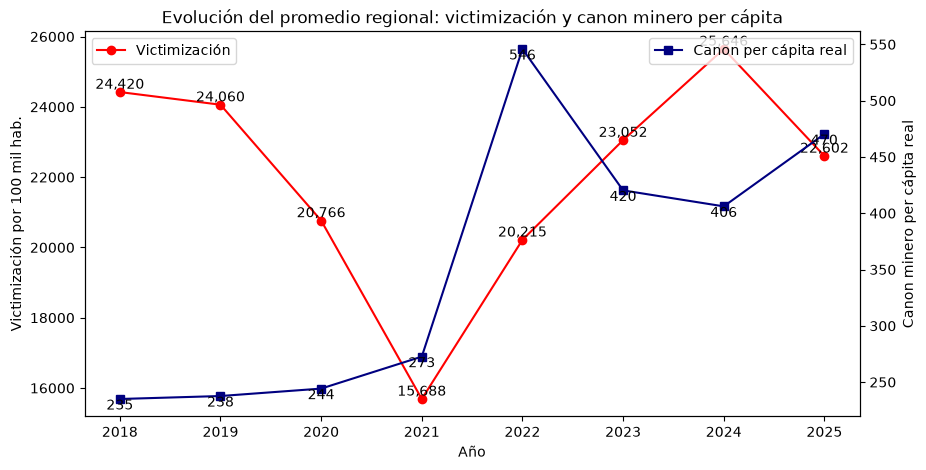

In [26]:
#Evolucion temporal
evol = df.groupby("anio").agg(
    victimizacion=("victim_100k","mean"),
    canon_pc=("canon_pc_real","mean")
).reset_index()

fig, ax1 = plt.subplots(figsize=(10,5))

ax1.plot(evol["anio"], evol["victimizacion"], marker="o", color="red", label="Victimización")
ax1.set_xlabel("Año")
ax1.set_ylabel("Victimización por 100 mil hab.")
for x, y in zip(evol["anio"], evol["victimizacion"]):
    ax1.text(x, y, f"{y:,.0f}", ha="center", va="bottom")

ax2 = ax1.twinx()
ax2.plot(evol["anio"], evol["canon_pc"], marker="s", color="navy", label="Canon per cápita real")
ax2.set_ylabel("Canon minero per cápita real")
for x, y in zip(evol["anio"], evol["canon_pc"]):
    ax2.text(x, y, f"{y:,.0f}", ha="center", va="top")

ax1.legend(loc="upper left")
ax2.legend(loc="upper right")
plt.title("Evolución del promedio regional: victimización y canon minero per cápita")
plt.show()

**Interpretación:**
El promedio regional de la victimización cae de 24,420 en 2018 a 15,688 en 2021 (-36%), y luego se recupera hasta un máximo de 25,646 en 2024. En 2025 baja a 22,602 (-12% frente a 2024). La caída de 2021 podría estar relacionada con las restricciones de la pandemia, pero esto es solo una hipótesis. El canon promedio per cápita se mantiene estable entre 2018 y 2021 (235 a 273), se duplica en 2022 (546) y luego se mantiene en un nivel más alto (406 a 470). En 2025 es el doble que en 2018. Las dos series no se mueven siempre juntas: entre 2018 y 2021 el canon sube y la victimización baja, y desde 2022 ambas suben. A simple vista no hay una relación clara en el tiempo. Además, estos son promedios simples de las 25 regiones y ocultan las diferencias entre ellas.

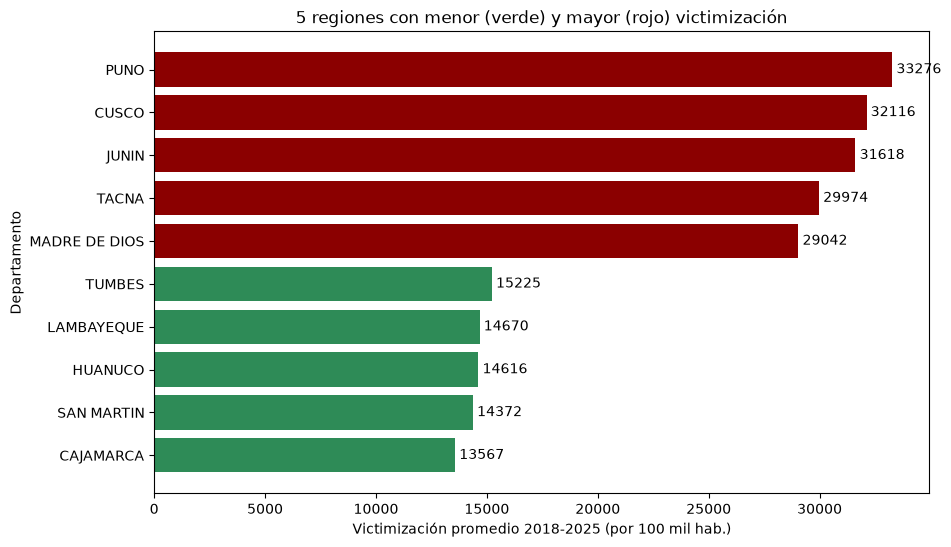

In [27]:
#Mejores y Peores regiones
prom_dpto = df.groupby("depto")["victim_100k"].mean().sort_values(ascending=True)
mejores = prom_dpto.head(5)
peores = prom_dpto.tail(5)
seleccion = pd.concat([mejores, peores])
colores = ["seagreen"]*5 + ["darkred"]*5

plt.figure(figsize=(10,6))
barras = plt.barh(seleccion.index, seleccion.values, color=colores)
plt.bar_label(barras, fmt="%.0f", padding=3)
plt.xlabel("Victimización promedio 2018-2025 (por 100 mil hab.)")
plt.ylabel("Departamento")
plt.title("5 regiones con menor (verde) y mayor (rojo) victimización")
plt.show()

In [28]:
# Media de datos de los top 5 mejores y peores
tabla_regiones = df.groupby("depto")[["victim_100k","canon_pc_real","pbi_sinmin_pc",
                                      "desempleo","migracion","pobreza","prod_min_pc"]].mean().round(2)
tabla_regiones.loc[seleccion.index]

,victim_100k,canon_pc_real,pbi_sinmin_pc,desempleo,migracion,pobreza,prod_min_pc
depto,,,,,,,
CAJAMARCA,13566.69,186.36,6822.42,4.86,1.38,42.12,1212.86
SAN MARTIN,14371.98,3.07,6830.97,3.45,4.92,23.48,45.42
HUANUCO,14616.09,9.06,7821.66,4.90,3.47,36.66,561.47
LAMBAYEQUE,14670.30,0.18,9611.94,5.04,2.59,14.06,26.81
TUMBES,15225.19,0.26,10625.89,7.22,1.65,23.19,397.38
MADRE DE DIOS,29042.44,29.65,8751.20,3.12,7.01,10.00,1799.05
TACNA,29974.29,1563.21,12696.54,5.96,3.18,20.43,9935.94
JUNIN,31618.08,163.61,8462.72,4.02,3.19,22.21,3037.32
CUSCO,32116.08,319.95,9109.10,3.80,1.85,22.60,6631.36


**Interpretación:**
Las regiones con mayor victimización promedio son Puno (33,276), Cusco (32,116), Junín (31,618), Tacna (29,974) y Madre de Dios (29,042). Las de menor victimización son Cajamarca (13,567), San Martín (14,372), Huánuco (14,616), Lambayeque (14,670) y Tumbes (15,225). El grupo de mayor victimización tiene, en promedio, mucho más canon (unos 450 frente a unos 40) y mucha más producción minera per cápita (unos 4,400 frente a unos 450). Hay dos matices: esa diferencia depende bastante de Tacna (canon de 1,563) y las otras variables no separan tanto a los grupos. El PBI sin minería es algo mayor en el grupo de peor victimización (unos 9,300 frente a 8,300) y la pobreza es menor (23% frente a 28%). El desempleo es parecido en ambos (4.8 y 5.1). Estos resultados muestran asociaciones y no demuestran causalidad.

**Casos que no encajan:** Puno es la región con más victimización, pero su canon (183) y su producción minera per cápita (548) son bajos. Madre de Dios tiene un canon bajo (30) pero la producción minera per cápita (1,799) y la migración (7.0, la más alta del grupo) son altas. Esto sugiere que parte de la actividad minera que podría estar asociada a la victimización no queda capturada por el canon, que mide solo minería formal, es una limitacion ya que se sabe que si existe mineria infromal de gran escaal en puno y madre de dios.

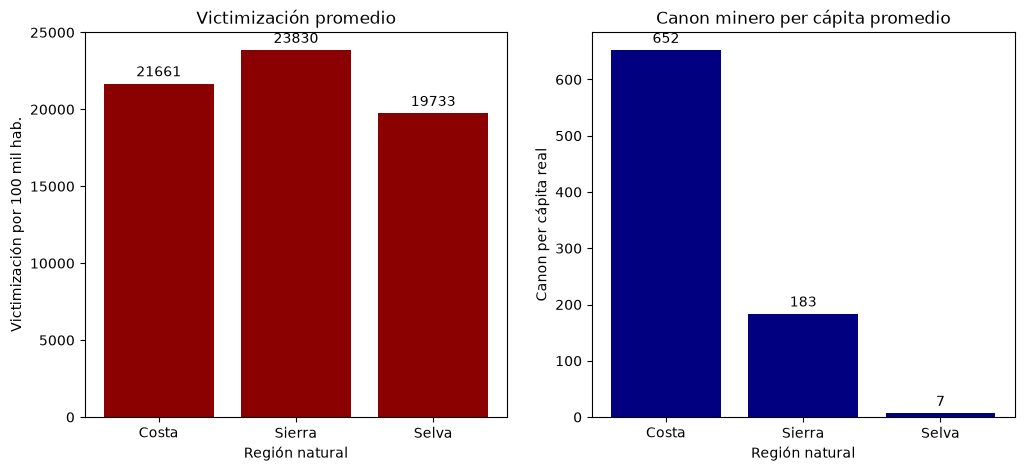

In [29]:
# Media de victimizacion y canon per capita por region natural
medias = df.groupby("region_natural")[["victim_100k","canon_pc_real"]].mean()
medias = medias.loc[["Costa","Sierra","Selva"]]

plt.figure(figsize=(12,5))

plt.subplot(121)
b1 = plt.bar(medias.index, medias["victim_100k"], color="darkred")
plt.bar_label(b1, fmt="%.0f", padding=3)
plt.xlabel("Región natural")
plt.ylabel("Victimización por 100 mil hab.")
plt.title("Victimización promedio")

plt.subplot(122)
b2 = plt.bar(medias.index, medias["canon_pc_real"], color="navy")
plt.bar_label(b2, fmt="%.0f", padding=3)
plt.xlabel("Región natural")
plt.ylabel("Canon per cápita real")
plt.title("Canon minero per cápita promedio")

plt.show()

**Interpretación:**
La sierra tiene la victimización promedio más alta (23,830), después la costa (21,661) y la selva es la más baja (19,733). La costa concentra el canon (652 per cápita), la sierra tiene 183 y la selva casi nada (7). La relación entre regiones naturales no es ordenada: la costa tiene el mayor canon pero una victimización intermedia, la sierra tiene un canon intermedio y la mayor victimización, y la selva casi no recibe canon y tiene la menor victimización. La sierra también es la más heterogénea (desv. est. 8,001, frente a 6,728 en la costa y 6,203 en la selva), es decir, dentro de ella hay regiones muy distintas. A nivel de regiones naturales no hay evidencia de que más canon implique más victimización.

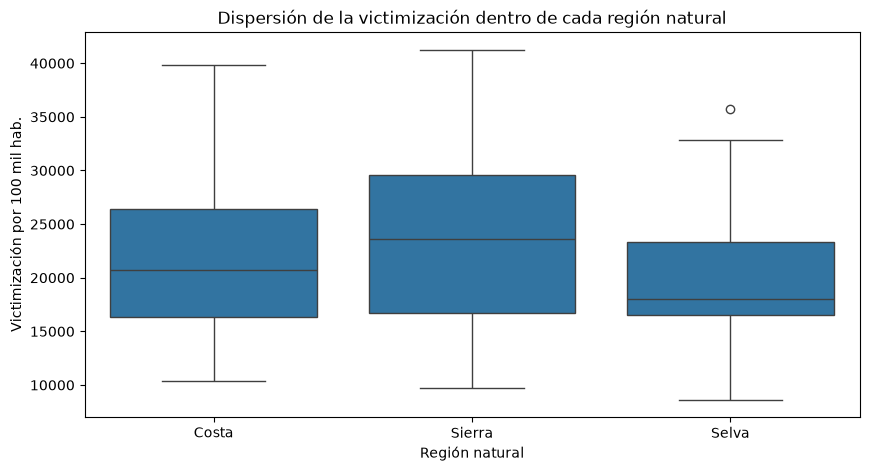

In [30]:
#Dispersion
import seaborn as sns

plt.figure(figsize=(10,5))
sns.boxplot(data=df, x="region_natural", y="victim_100k", order=["Costa","Sierra","Selva"])
plt.xlabel("Región natural")
plt.ylabel("Victimización por 100 mil hab.")
plt.title("Dispersión de la victimización dentro de cada región natural")
plt.show()

**Interpretación:**
La sierra tiene la mediana más alta de victimización (unos 23,600), seguida de la costa (unos 20,700) y la selva (unos 18,000). Esto coincide con los promedios de 4.4. Sin embargo, las cajas se superponen bastante: gran parte de los valores de las tres regiones naturales está entre 16 mil y 23 mil, por lo que las diferencias entre medianas (unos 5 mil entre sierra y selva) son pequeñas frente a la dispersión dentro de cada grupo. La sierra es la más heterogénea (caja de unos 16,700 a 29,600 y extremos de 9.7 mil a 41.3 mil), después la costa (16,300 a 26,400) y la selva es la más homogénea (16,500 a 23,300). La selva presenta un valor atípico cerca de 35,700 (Madre de Dios en 2019). Hay regiones de alta y de baja victimización en las tres regiones naturales, por lo que la región natural por sí sola no explica los niveles.

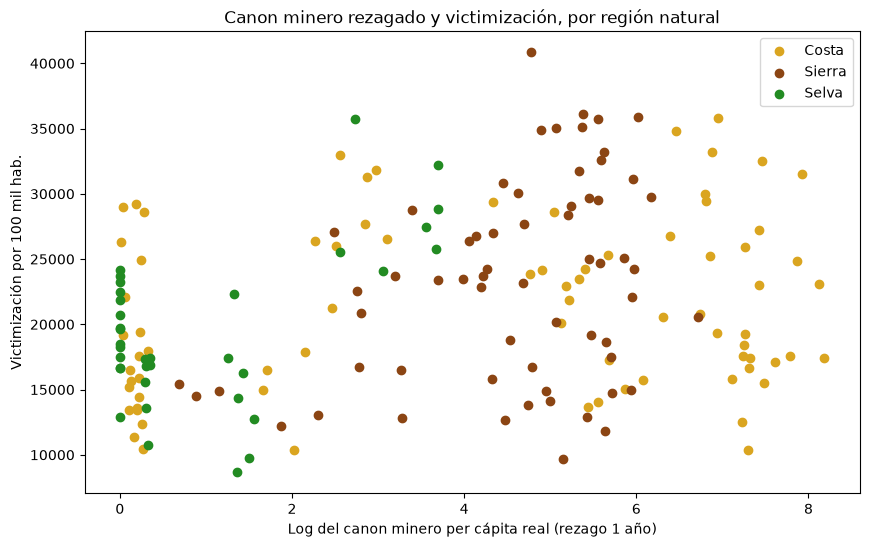

In [31]:
#Canon vs victimizacion
costa = df[df["region_natural"]=="Costa"]
sierra = df[df["region_natural"]=="Sierra"]
selva = df[df["region_natural"]=="Selva"]

plt.figure(figsize=(10,6))
plt.scatter(costa["ln_canon_l1"], costa["victim_100k"], color="goldenrod", label="Costa")
plt.scatter(sierra["ln_canon_l1"], sierra["victim_100k"], color="saddlebrown", label="Sierra")
plt.scatter(selva["ln_canon_l1"], selva["victim_100k"], color="forestgreen", label="Selva")
plt.xlabel("Log del canon minero per cápita real (rezago 1 año)")
plt.ylabel("Victimización por 100 mil hab.")
plt.title("Canon minero rezagado y victimización, por región natural")
plt.legend()
plt.show()

**Interpretación:**
La nube de puntos es muy ancha y la tendencia ascendente es leve: con r = 0.30, la relación es débil. Los puntos apilados en x = 0 corresponden a observaciones sin canon (el logaritmo de cero se transforma en 0) y su victimización va de unos 9 mil a casi 30 mil. Es decir, regiones sin canon ya presentan una variación enorme, que el canon no explica. Con canon alto (x mayor a 5.5, unos 245 soles per cápita o más) la victimización también va de 10 mil a 36 mil, así que no se aprecia un salto claro. Los valores más altos (más de 35 mil) aparecen con canon intermedio, sobre todo en la sierra (marrón). La selva (verde) se concentra en canon bajo y victimización moderada, con un punto alto cerca de 35 mil. Los tres grupos se mezclan en toda la nube. A simple vista hay una asociación positiva leve y muy dispersa, que no controla por región ni por año.

In [32]:
df[["victim_100k","ln_canon_l1"]].corr()

,victim_100k,ln_canon_l1
victim_100k,1.000000,0.298635
ln_canon_l1,0.298635,1.000000


**Interpretación:**
La correlación entre el logaritmo del canon rezagado y la victimización es de 0.30 (175 observaciones): positiva pero débil. Con r = 0.30, el canon explica linealmente cerca del 9% de la variación de la victimización (r² ≈ 0.09). Es una correlación conjunta, que no controla por diferencias entre regiones ni entre años, así que es solo un primer indicio. Los modelos con efectos fijos de la sección 5 permiten ver si la asociación se mantiene.

In [33]:
# Mapa victimizacion
import plotly.express as px
import requests

link = "https://bit.ly/3nzLV1j"
departamento = requests.get(link).json()

mapa_victim = df.groupby("depto")["victim_100k"].mean().reset_index()

mapa = px.choropleth_mapbox(
    data_frame=mapa_victim,
    geojson=departamento,
    locations="depto",
    featureidkey="properties.NOMBDEP",
    color="victim_100k",
    color_continuous_scale="Reds",
    width=650,
    height=950,
    center={"lat": -9.1900, "lon": -75.0152},
    mapbox_style="carto-positron",
    zoom=4
)
mapa.show()

In [34]:
tabla_victim = df.pivot(index="depto", columns="anio", values="victim_100k")
res_v = pd.DataFrame({
    "prom": tabla_victim.mean(axis=1),
    "y2018": tabla_victim[2018],
    "y2025": tabla_victim[2025]
})
res_v["cambio"] = res_v["y2025"] - res_v["y2018"]
res_v.round(0).astype(int)

,prom,y2018,y2025,cambio
depto,,,,
AMAZONAS,15759,17806,16783,-1023
ANCASH,17809,22801,16635,-6165
APURIMAC,22792,22696,24228,1531
AREQUIPA,26583,26006,33195,7190
AYACUCHO,24421,27149,27711,562
CAJAMARCA,13567,16760,13805,-2955
CALLAO,26019,28886,24918,-3967
CUSCO,32116,37170,31161,-6009
HUANCAVELICA,24014,28696,23733,-4963


**Interpretación:**
Entre 2018 y 2025 la victimización bajó en 16 de las 25 regiones y subió en 9. Las mayores caídas se dieron en regiones que partían de niveles muy altos: Tacna (-13,926), Junín (-9,674), Puno (-9,515) y Cusco (-6,009), por lo que parece haber cierta convergencia hacia abajo. Aun así, Puno (41,276 en 2018) seguía alto en 2025 (31,760), junto con Cusco, Junín y Madre de Dios. Las mayores alzas fueron Moquegua (+7,741), Arequipa (+7,190, que en 2025 pasa a ser la más alta con 33,195), Piura (+5,193) y San Martín (+3,992). Las regiones con menor victimización en promedio son Cajamarca, San Martín, Huánuco, Lambayeque y Tumbes.

In [35]:
# Mapa canon
import plotly.express as px
import requests

link = "https://bit.ly/3nzLV1j"
departamento = requests.get(link).json()

mapa_victim = df.groupby("depto")["canon_pc_real"].mean().reset_index()

mapa = px.choropleth_mapbox(
    data_frame=mapa_victim,
    geojson=departamento,
    locations="depto",
    featureidkey="properties.NOMBDEP",
    color="canon_pc_real",
    color_continuous_scale="Blues",
    width=650,
    height=950,
    center={"lat": -9.1900, "lon": -75.0152},
    mapbox_style="carto-positron",
    zoom=4
)
mapa.show()

In [36]:
tabla_canon = df.pivot(index="depto", columns="anio", values="canon_pc_real")
res_c = pd.DataFrame({
    "prom": tabla_canon.mean(axis=1),
    "y2018": tabla_canon[2018],
    "y2025": tabla_canon[2025]
})
res_c["cambio"] = res_c["y2025"] - res_c["y2018"]
res_c.round(0).astype(int)

,prom,y2018,y2025,cambio
depto,,,,
AMAZONAS,0,0,0,0
ANCASH,1681,1671,1467,-204
APURIMAC,309,76,660,584
AREQUIPA,705,597,934,337
AYACUCHO,136,70,133,63
CAJAMARCA,186,141,247,106
CALLAO,0,0,0,0
CUSCO,320,215,330,115
HUANCAVELICA,40,11,146,135


**Interpretación:**
El canon está muy concentrado: Moquegua (promedio 2,390), Áncash (1,681) y Tacna (1,563) están muy por encima del resto, seguidas de Arequipa (705) e Ica (595). Seis regiones prácticamente no reciben canon (Callao, Loreto, Ucayali, Amazonas, Tumbes y Lambayeque). Entre 2018 y 2025 el canon creció en 14 regiones, con aumentos fuertes en Moquegua (de 1,218 a 3,769), Tacna (de 639 a 1,933) y Apurímac (de 76 a 660), mientras que Áncash bajó (de 1,671 a 1,467). Al comparar con la victimización no hay un patrón claro: de las 14 regiones con canon creciente, en 8 la victimización bajó (Tacna, Puno, Cusco, Junín, entre otras) y en 6 subió (Moquegua, Arequipa, Apurímac, Ica, Piura y Ayacucho). Moquegua y Áncash, las de mayor canon, tienen victimización promedio en el tercio inferior de las regiones, pero en Moquegua la victimización sube en 2025. Esto indica que la asociación es heterogénea entre regiones.

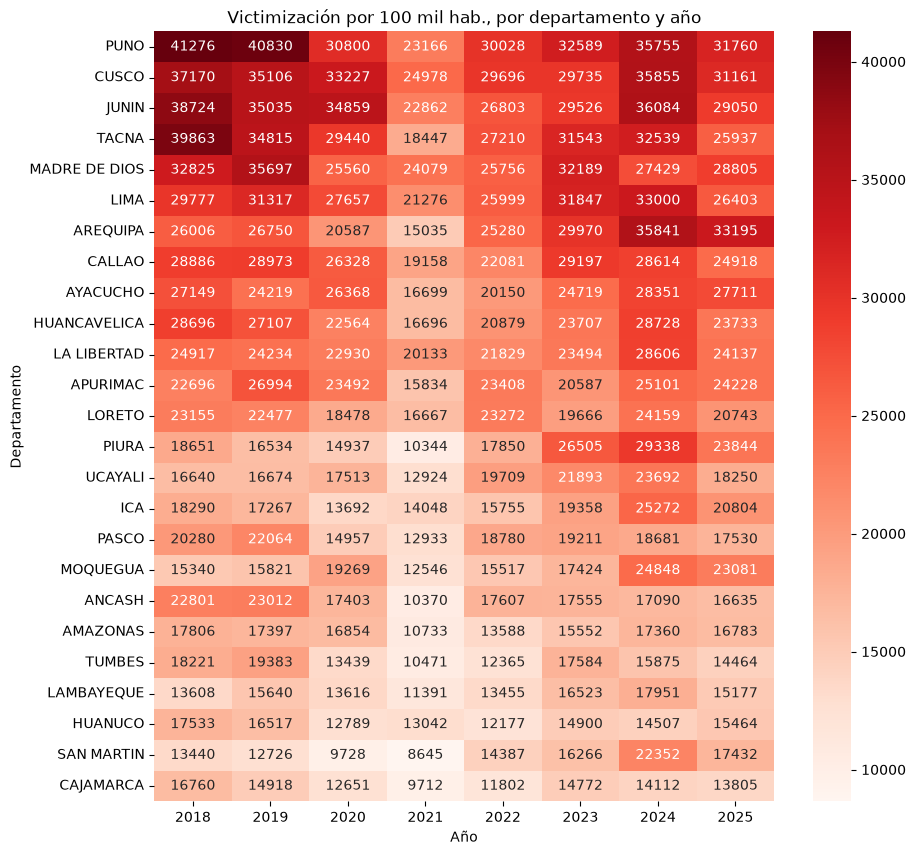

In [37]:
import seaborn as sns

tabla_victim = df.pivot_table(index="depto", columns="anio", values="victim_100k")
orden = tabla_victim.mean(axis=1).sort_values(ascending=False).index
tabla_victim = tabla_victim.loc[orden]

plt.figure(figsize=(10,10))
sns.heatmap(tabla_victim, annot=True, fmt=".0f", cmap="Reds")
plt.title("Victimización por 100 mil hab., por departamento y año")
plt.xlabel("Año")
plt.ylabel("Departamento")
plt.show()

**Interpretación:**
El patrón más claro es un golpe común en 2021: ese año es el mínimo en 23 de las 25 regiones (las excepciones son Ica, con su mínimo en 2020, y Huánuco, en 2022). Podría estar relacionado con las restricciones de la pandemia, pero es solo una hipótesis. Después viene una recuperación hasta 2024, año en que 12 regiones alcanzan su máximo. Hay saltos muy grandes: Piura pasa de 10,344 (2021) a 29,338 (2024), Arequipa de 15,035 a 35,841, San Martín de 8,645 a 22,352 y Moquegua de 12,546 a 24,848. En 2025 la victimización baja en 23 de 25 regiones (solo suben Madre de Dios y Huánuco). Al inicio del periodo los valores más altos estaban en Puno, Cusco, Junín y Tacna (37 mil a 41 mil en 2018), y en 2025 siguen entre los más altos (salvo Tacna, que cae a 25,937) junto con Arequipa, que pasa a ser la más alta (33,195). En el otro extremo, Cajamarca, Huánuco, Lambayeque, Amazonas y Tumbes nunca superan unos 19,400 en todo el periodo.

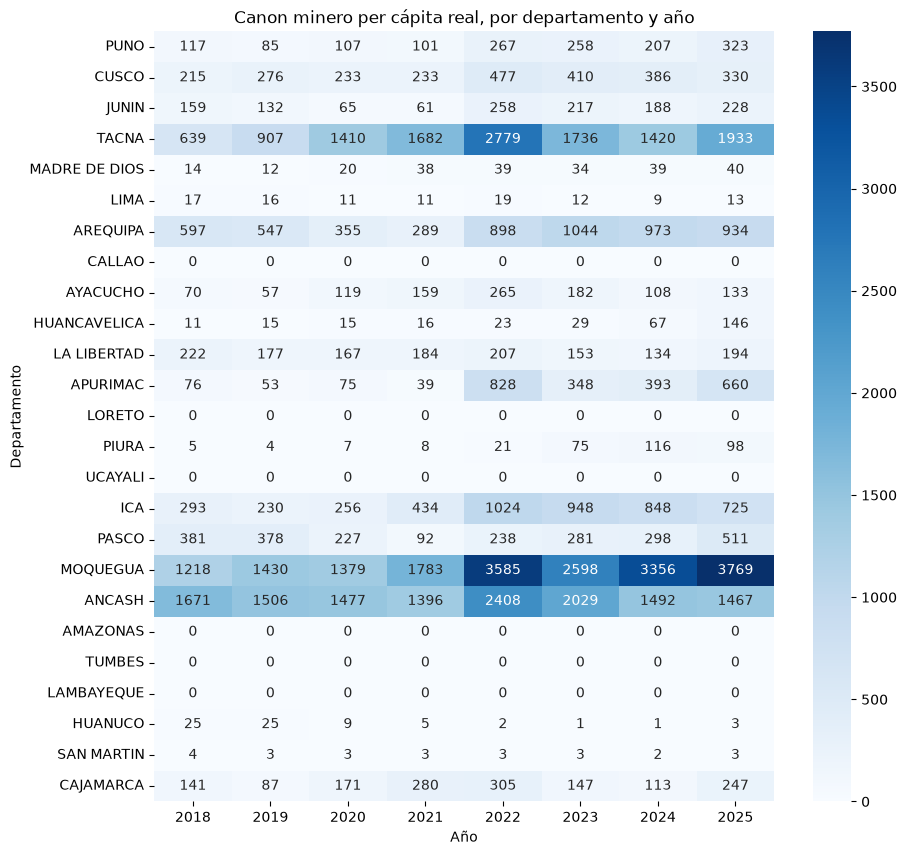

In [38]:
tabla_canon = df.pivot_table(index="depto", columns="anio", values="canon_pc_real")
tabla_canon = tabla_canon.loc[orden]

plt.figure(figsize=(10,10))
sns.heatmap(tabla_canon, annot=True, fmt=".0f", cmap="Blues")
plt.title("Canon minero per cápita real, por departamento y año")
plt.xlabel("Año")
plt.ylabel("Departamento")
plt.show()

**Interpretación:**
El canon está concentrado en pocas regiones: Moquegua, Tacna, Áncash, Arequipa e Ica reciben los montos más altos, y seis regiones (Callao, Loreto, Ucayali, Amazonas, Tumbes y Lambayeque) no reciben canon en ningún año. Lima, Huánuco, San Martín y Madre de Dios reciben montos casi nulos. En 2022 hay un salto general en las regiones con canon relevante: Moquegua pasa de 1,783 a 3,585, Tacna de 1,682 a 2,779, Arequipa de 289 a 898, Apurímac de 39 a 828, Cusco de 233 a 477, Junín de 61 a 258 y Puno de 101 a 267. Una posible explicación son los mayores precios de los minerales y las mayores utilidades del periodo anterior, pero esta base no permite comprobarlo. Después de 2022 el canon se mantiene por encima de los niveles de 2018-2021 en la mayoría de las regiones; Moquegua llega a 3,769 en 2025 y Tacna a 1,933, ambos unas 3 veces su valor de 2018. La excepción es Áncash, que baja de 2,408 (2022) a 1,467 (2025), por debajo de su nivel de 2018. Al comparar con la victimización no hay un patrón común: en Tacna y Puno el canon crece mientras la victimización baja (-35% y -23% entre 2018 y 2025), mientras que en Moquegua, Arequipa y Apurímac el canon crece y la victimización también (+50%, +28% y +7%). En Áncash ambos bajan. Madre de Dios tiene un canon muy bajo (entre 12 y 40) y una victimización alta (entre 25 mil y 36 mil), lo que coincide con la limitación de la minería ilegal discutida.

**Interpretaciones de los graficos:**
- **Evolución del promedio regional: victimización y canon minero per cápita:** .....
- **5 regiones con menor (verde) y mayor (rojo) victimización:**....
- **Victimización promedio / Canon minero per cápita promedio, por región natural:** .....
- **Dispersión de la victimización dentro de cada región natural:** .....
- **Canon minero rezagado y victimización, por región natural:** .....
- **Mapa de victimizacion:** .....
- **Mapa del canon:** .....


# 5. Analisis Estadistico

In [39]:
# Muestra 2021-2025 y variables del modelo

base = df[df["anio"] >= 2021].copy()
y = base["victim_100k"]
vars_x = ["ln_canon_l1","pobreza","desempleo","gasto_seg_pc_real","migracion"]

In [40]:
# Para medir que tan fuerte es la relacion entre variables
base[["victim_100k"] + vars_x].corr().round(2)

,victim_100k,ln_canon_l1,pobreza,desempleo,gasto_seg_pc_real,migracion
victim_100k,1.00,0.31,-0.08,0.27,0.01,-0.03
ln_canon_l1,0.31,1.00,-0.22,0.03,0.06,-0.26
pobreza,-0.08,-0.22,1.00,0.17,-0.27,-0.22
desempleo,0.27,0.03,0.17,1.00,0.16,-0.29
gasto_seg_pc_real,0.01,0.06,-0.27,0.16,1.00,-0.32
migracion,-0.03,-0.26,-0.22,-0.29,-0.32,1.00


In [41]:
# Regresion lineal multiple:
import statsmodels.api as sm
X = base[vars_x]
X = sm.add_constant(X)
regresion_multiple = sm.OLS(y,X).fit()

print(regresion_multiple.summary())

                            OLS Regression Results                            
Dep. Variable:            victim_100k   R-squared:                       0.184
Model:                            OLS   Adj. R-squared:                  0.150
Method:                 Least Squares   F-statistic:                     5.378
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           0.000171
Time:                        17:47:08   Log-Likelihood:                -1266.8
No. Observations:                 125   AIC:                             2546.
Df Residuals:                     119   BIC:                             2563.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const              1.227e+04   3909.73

**Modelo:** victimización por 100 mil habitantes = β₀ + β₁·ln(canon per cápita real, rezagado un año) + β₂·pobreza + β₃·desempleo + β₄·gasto en seguridad per cápita + β₅·migración + ε.

**Interpretacion:**

**Canon minero:** el coeficiente es β₁ = 845, de signo positivo: cuando el canon per cápita se multiplica por ≈2.7 (aumenta 1 en logaritmo), la victimización aumenta en promedio unos 845 casos por 100 mil habitantes (cerca de 0.8 puntos porcentuales), manteniendo constantes las demás variables. Es estadísticamente significativo (p < 0.001), por lo que se rechaza H0 y la evidencia apoya H1b (mayor canon asociado con mayor victimización).

**Otras variables:**
- **Desempleo:** Signo positivo (β = 1 017). Un punto porcentual más de desempleo se asocia con unos 1 017 casos más por 100 mil habitantes y es significativo (p= 0.001)
- **Pobreza:** Signo negativo (β = −25) pero no es significativo (p=0.692)
- **Gasto en seguridad per cápita:** Signo negativo (β = −1.2) pero no es significativo (p=0.716)
- **Migración:** Signo positivo (β = 530), pero no es significativo (p=0.214).

**Fuerza de la relación:** el R² es 0.184, es decir, el modelo explica el 18.4 % de la variación de la victimización (R² ajustado: 0.150). Es una capacidad explicativa baja a moderada. Mientras que, el estadístico F es significativo (p = 0.0002), por lo que las variables en conjunto aportan información; según el estadístico t, destacan el canon (t = 3.6) y el desempleo (t = 3.5).

**Advertencia y limitaciones:** El modelo no controla por efectos fijos de departamento ni de año (por lo que no controla por características de cada departamento que no cambian en el tiempo, ni por tendencias nacionales comunes a todos). Tampoco controla por minería ilegal o la capacidad del Estado. Además, los errores estándar no son robustos pues el estadístico de Durbin-Watson (0.95) sugiere que los errores de un mismo departamento están correlacionados entre años, lo que puede hacer que los p-valores sean demasiado optimistas.

# 6. Analisis Predictivo

In [42]:
# Separamos los datos en dos grupos: Entrenamiento (para aprender y estimar) y Prueba (para evaluar que tan bien predice)
train = base[base["anio"] <= 2024]
test  = base[base["anio"] == 2025]

X_train = train[vars_x]
y_train = train["victim_100k"]

X_test = test[vars_x]
y_test = test["victim_100k"]

print ("observaciones de entrenamiento:", len(X_train))
print ("observaciones de prueba:", len(X_test))

observaciones de entrenamiento: 100
observaciones de prueba: 25


In [43]:
# Para entrenar al modelo
from sklearn.linear_model import LinearRegression
modelo_pred = LinearRegression()
modelo_pred.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 830.32, 14.11,1060.51, 0.19, 632.42]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['ln_canon_l1','pobreza','desempleo','gasto_seg_pc_real','migracion']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,9896
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [44]:
#Para coeficientes
print(modelo_pred.intercept_)

coeficientes = pd.DataFrame({
    "Variable":X_train.columns,
    "Coeficiente":modelo_pred.coef_
})
coeficientes

9896.388331291688


,Variable,Coeficiente
0,ln_canon_l1,830.318130
1,pobreza,14.108981
2,desempleo,1060.508159
3,gasto_seg_pc_real,0.185798
4,migracion,632.421843


In [45]:
#Predecimos 2025 y calculamos el error:
# Predecimos 2025:
predicciones = modelo_pred.predict(X_test)

comparacion = pd.DataFrame({
    "DEPARTAMENTO":df.loc[y_test.index, "depto"],
    "Valor_real" : y_test,
    "Predicho": predicciones
})
# Para calcular los residuos / errores:
comparacion["error"] = comparacion["Valor_real"] - comparacion["Predicho"]
comparacion

,DEPARTAMENTO,Valor_real,Predicho,error
7,AMAZONAS,16783.042306,16609.933449,173.108857
15,ANCASH,16635.281394,21754.961389,-5119.679995
23,APURIMAC,24227.570698,18964.827520,5262.743178
31,AREQUIPA,33195.338912,24952.981915,8242.356997
39,AYACUCHO,27710.996750,20231.647036,7479.349714
47,CAJAMARCA,13805.352878,19740.980480,-5935.627602
55,CALLAO,24918.403434,20654.993070,4263.410365
63,CUSCO,31161.294416,19876.453153,11284.841263
71,HUANCAVELICA,23732.956056,18341.613043,5391.343013
79,HUANUCO,15463.879714,19521.707581,-4057.827866


**Interpretacion:** El modelo predice con bastante precisión a algunos departamentos, como Amazonas, Ucayali,Piura y San Martín. Los mayores errores son de subestimación (donde el valor real supera al predicho) en departamentos con alta victimización, como Cusco, Madre de Dios, Arequipa, Junín y Ayacucho. También hay sobreestimaciones en departamentos con baja victimización, como Pasco, Cajamarca y Áncash.


In [46]:
#Las metricas de desempeño:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae  = mean_absolute_error(y_test, predicciones)
rmse = np.sqrt(mean_squared_error(y_test, predicciones))
r2   = r2_score(y_test, predicciones)

print("MAE :", round(mae,0))
print("RMSE:", round(rmse,0))
print("R2  :", round(r2,3))

MAE : 4280.0
RMSE: 5197.0
R2  : 0.168


**Interpretacion:** En las metricas del desempeño; el MAE es de 4 280, es decir, el modelo se equivoca en promedio en unos 4 280 casos por 100 mil habitantes, cerca del 19 % de la victimización promedio observada en 2025 (22 602). El RMSE es de 5 197, mayor que el MAE, esto es señal de que hay algunos errores grandes, como el de Cusco. El R² de 0.168 indica que el modelo explica solo el 17 % de la variación de la victimización entre departamentos en 2025, un valor parecido al de la regresión explicativa (0.184), lo que sugiere que el modelo no está sobreajustado, pero sí que su capacidad predictiva es baja.



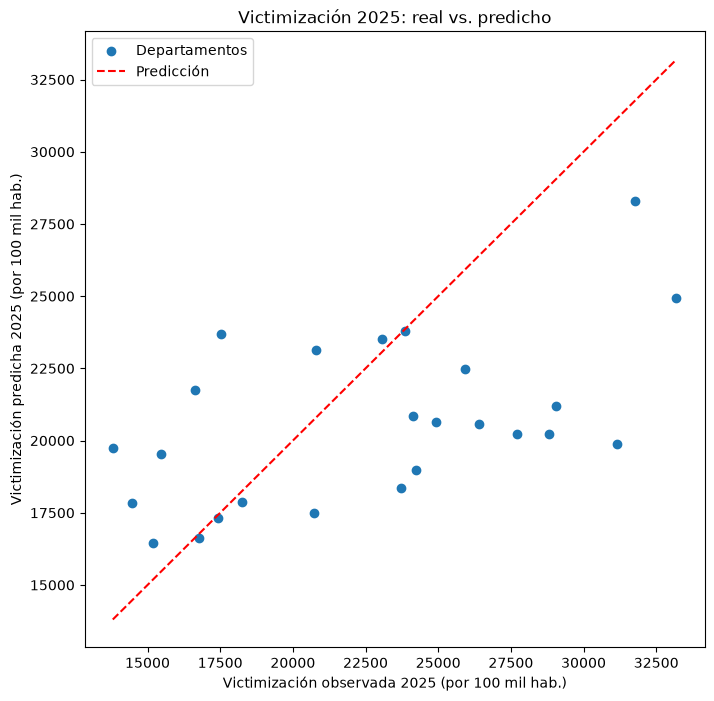

In [47]:
#Podemos comparar en un grafico de los valores reales con los predichos
plt.figure (figsize=(8,8))

plt.scatter(y_test, predicciones, label="Departamentos")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "--", color="red", label="Predicción"
)

plt.xlabel("Victimización observada 2025 (por 100 mil hab.)")
plt.ylabel("Victimización predicha 2025 (por 100 mil hab.)")
plt.title("Victimización 2025: real vs. predicho")
plt.legend()

plt.show()

**Interpretacion:** En el grafico, los puntos se alejan de la línea de predicción perfecta. Los departamentos con victimización observada alta (más de 24 000) quedan casi todos por debajo de la línea, o sea, el modelo los subestima, mientras que los de victimización baja (menos de 20 000) quedan por encima, es decir, los sobreestima. Las predicciones se concentran entre 16 000 y 28 000, un rango menor al de los valores observados (13 800 a 33 200): el modelo tiende a acercar sus predicciones al promedio y no logra reproducir los extremos.



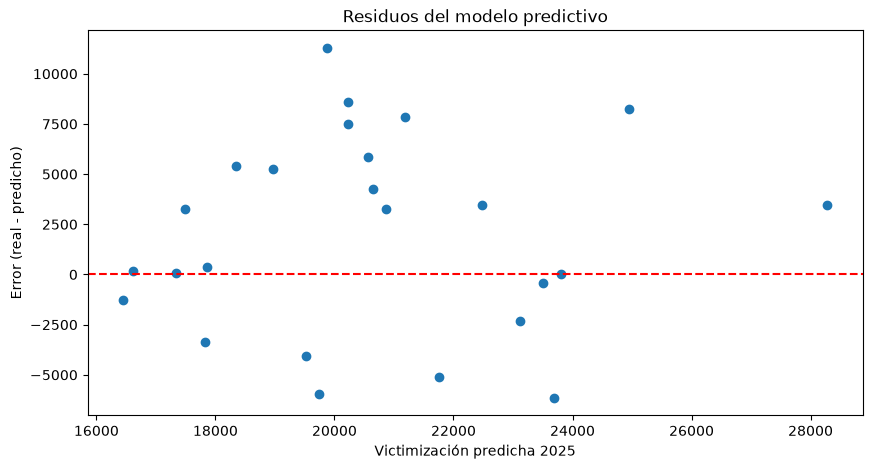

In [48]:
# Podemos graficar los residuos para validar el modelo
plt.figure (figsize=(10,5))

plt.scatter(predicciones,
            comparacion["error"])

plt.axhline(y=0,linestyle="--", color="red")

plt.xlabel("Victimización predicha 2025")
plt.ylabel("Error (real - predicho)")
plt.title("Residuos del modelo predictivo")

plt.show()

**Interpretacion:** En el grafico, los errores no se distribuyen de forma simétrica alrededor de cero: aproximadamente dos tercios de los puntos quedan sobre la línea, es decir, el modelo subestima la victimización de 2025 en la mayoría de los departamentos. Los errores más grandes se concentran entre predicciones de 19 000 y 21 500 (Cusco, Madre de Dios, Ayacucho y Junín), todos con subestimación, lo que indica que el modelo no captura bien a los departamentos de mayor victimización. Con solo 25 observaciones, estos patrones deben tomarse con cautela.



# 7. Conclusiones e hipotesis

**Principales hallazgos:**
- **Patrón territorial.** La victimización es alta y muy desigual entre departamentos. Entre 2018 y 2025, el promedio departamental de casos de victimizacion por 100 mil habitantes va de 13 567 (Cajamarca) a 33 276 casos (Puno). Los cinco departamentos con mayores niveles promedio de victimización por 100 mil habitantes son Puno (33,276), Cusco (32,116), Junín (31,618), Tacna (29,974) y Madre de Dios (29,042). Mientras que, los cinco con menores tasas son Cajamarca (13,567), San Martín (14,372), Huánuco (14,616), Lambayeque (14,670) y Tumbes (15,225). Por región natural, la Sierra tiene la mayor victimización promedio (23 830), seguida de la Costa (21 661) y la Selva (19 733).


**a. ¿Por qué considera que estas variables podrían estar asociadas con el problema? Sustente su respuesta.**
- El canon puede reducir la victimización si financia servicios y seguridad (H1a) o aumentarla si trae migración, conflictos y economías ilegales (H1b). Los datos dan pistas de ambos lados. Madre de Dios tiene la mayor migración del grupo de alta victimización (7.0) y el desempleo muestra una correlación positiva con la victimización (0.27). El gasto en seguridad, la pobreza y la migración se incluyen como controles. Sus correlaciones con la victimización son casi nulas (0.01, −0.08 y −0.03), así que se las mantiene como controles y no por una asociación visible.

**b. ¿Qué patrones observa en las regiones con peores indicadores?**
- Las cinco regiones con mayor victimización (Puno, Cusco, Junín, Tacna y Madre de Dios) tienen en promedio más canon (unos 450 frente a unos 40) y más producción minera per cápita (unos 4,400 frente a unos 450) que las cinco de menor victimización. Esa diferencia depende mucho de Tacna (canon de 1,563). También hay casos que no encajan: Puno tiene la mayor victimización con canon bajo (183). Otro patrón es temporal: 2021 es el mínimo en 23 de 25 regiones y 2024 el máximo en 12.

**c. ¿Qué tan fuerte parece la relación entre las variables a simple vista?**
- Es débil. La correlación entre el canon rezagado (en logaritmo) y la victimización es 0.30, lo que explica cerca del 9% de la variación (r² ≈ 0.09). El diagrama de dispersión muestra una nube muy ancha con tendencia ascendente leve. Entre regiones naturales no hay orden: la costa tiene más canon (652) pero una victimización intermedia (21,661), y la sierra tiene la más alta (23,830) con canon intermedio (183). En la regresión múltiple el canon y el desempleo son significativos (p < 0.01), pero el modelo explica solo el 18.4% de la variación (R² ajustado 0.150).

**d. ¿Existe heterogeneidad en las regiones? ¿Cuáles son las más rezagadas?**
- Sí, mucha. La victimización promedio va de 13,567 (Cajamarca) a 33,276 (Puno), y la sierra es la región natural más dispersa (desv. est. 8,001). El canon está muy concentrado: Moquegua (2,390), Áncash (1,681) y Tacna (1,563) frente a seis regiones sin canon en ningún año (Callao, Loreto, Ucayali, Amazonas, Tumbes y Lambayeque). La relación tampoco va en la misma dirección. De las 14 regiones con canon creciente entre 2018 y 2025, en 8 la victimización bajó y en 6 subió. Las más rezagadas son Puno (31,760 en 2025), Cusco (31,161), Junín (29,050) y Madre de Dios (28,805), que siguen entre las más altas pese a bajar desde 2018. Arequipa pasó a ser la más alta en 2025 (33,195, +7,190 desde 2018), y Moquegua subió 7,741 en el mismo periodo.

**e. ¿Puede formular una hipótesis preliminar a partir de la evidencia visual?**
- Las regiones con más canon per cápita rezagado tienden a mostrar algo más de victimización (H1b), pero la asociación es débil, heterogénea entre regiones y en parte atribuible a pocas regiones y a shocks comunes de 2021-2022. Proponemos que, controlando por diferencias entre regiones y por año, la asociación del canon con la victimización será menor que la observada en los gráficos. El desempleo también aparece asociado positivamente con la victimización.

**f. ¿Qué tan bien predice la regresión lineal el indicador para 2025 al comparar los valores observados y predichos?**
- La regresión predice de forma limitada. Con las variables del modelo (canon rezagado, pobreza, desempleo, gasto en seguridad y migración), entrenado con 2021-2024 (100 observaciones) y evaluado en 2025 (25 departamentos), se obtiene un MAE de 4 280, un RMSE de 5 197 y un R² de 0.168. El MAE equivale a cerca del 19% de la victimización promedio de 2025 (22 602). Predice bien algunos departamentos como Piura, San Martín, Amazonas y Ucayali (con errores menores a 400), pero se equivoca mucho en los extremos. El RMSE, mayor que el MAE, indica que hay errores grandes, y el R² indica que el modelo explica solo el 17% de la variación entre departamentos. 

**Limitaciones:**
- **En la prediccion:** la regresión tiene una capacidad predictiva limitada: mejora al uso del promedio general, pero comete errores grandes en los departamentos de victimización extrema. Además, una buena predicción no implicaría una relación causal: aunque el canon y el desempleo ayudan a predecir, eso no demuestra que causen la victimización.
- **minería ilegal e informal:**
El canon minero mide la renta de la minería formal y no incluye la minería informal ni la ilegal. Esto es relevante porque regiones como Puno y Madre de Dios tienen altos niveles de victimización pero poco canon, lo que sugiere que parte de la actividad minera que podría estar relacionada con la victimización no queda capturada. No se pudo incorporar una variable de minería ilegal por falta de datos regionales anuales comparables. Por eso los resultados se interpretan solo como asociaciones con la minería formal y no se puede descartar que la minería ilegal afecte la relación.
